# Evaluación del servicio de IA

Notebook de evaluación de la puntuación (1–5 estrellas) y la moderación de `ai-service`, con un conjunto de 200 reseñas etiquetadas a mano.

Contenido:
1. Carga y validación del dataset
2. Evaluación de la puntuación
3. Evaluación de la moderación y elección del umbral
4. Conclusiones

## 1. Carga y validación del dataset

In [1]:
from pathlib import Path

import pandas as pd

DATA_PATH = Path("../data/reviews.csv")

El CSV se guardó con BOM y con las columnas alineadas con espacios, así que se lee con `utf-8-sig` y se limpian los espacios sobrantes.

In [2]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", skipinitialspace=True)
df.columns = df.columns.str.strip()
df["text"] = df["text"].str.strip()
df.head()

,id,text,stars,flagged
0,1,Concierto entretenido pero el sonido desde el ...,4.0,0
1,2,!!!!!!!!!!!!!! comprad ya !!!!!!!!!!!!!! ofert...,NaN,1
2,3,"La aplicación es perfecta, rápida, bonita y si...",5.0,0
3,4,ñññññññññññññ estoy probando el comentario ñññ...,NaN,1
4,5,"La cafetera es fantástica, el café sale perfec...",5.0,0


In [3]:
print(f"Filas: {len(df)}")
print(f"Ids únicos: {df['id'].is_unique}")
print(f"Textos duplicados: {df['text'].duplicated().sum()}")
print(f"Textos vacíos: {(df['text'].str.len() == 0).sum()}")
print(f"Longitud mín/máx: {df['text'].str.len().min()} / {df['text'].str.len().max()}")

Filas: 200
Ids únicos: True
Textos duplicados: 0
Textos vacíos: 0
Longitud mín/máx: 47 / 95


Etiquetas válidas: `stars` entre 1 y 5 (o vacía) y `flagged` igual a 0 o 1.

In [4]:
assert df["flagged"].isin([0, 1]).all(), "flagged debe ser 0 o 1 en todas las filas"
assert df["stars"].dropna().isin([1, 2, 3, 4, 5]).all(), "stars debe estar entre 1 y 5"
df["stars"] = df["stars"].astype("Int64")

print("Distribución de flagged:")
print(df["flagged"].value_counts().sort_index().to_string())
print("\nDistribución de stars:")
print(df["stars"].value_counts(dropna=False).sort_index().to_string())

Distribución de flagged:
flagged
0    154
1     46

Distribución de stars:
stars
1       50
2       31
3       14
4       32
5       46
<NA>    27


Cruce entre las dos etiquetas: las reseñas marcadas con `stars` son las que habría que comparar si no se hubieran bloqueado, y las que no tienen `stars` no se pueden puntuar.

In [5]:
pd.crosstab(df["flagged"], df["stars"].isna().map({True: "sin stars", False: "con stars"}))

stars,con stars,sin stars
flagged,,
0,154,0
1,19,27


## 2. Evaluación de la puntuación

Se importa `rate()` directamente de `ai-service`, de modo que se evalúa el código real. El modelo se carga al importar el módulo.

In [6]:
import sys

sys.path.append(str(Path("../../ai-service").resolve()))
from app.rating import rate

IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

C:\Users\samu1\miniconda3\envs\review-ai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  34%|███▍      | 69/201 [00:00<00:00, 673.05it/s]

Loading weights:  68%|██████▊   | 137/201 [00:00<00:00, 453.90it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 688.40it/s]

Se evalúan todas las reseñas que tienen `stars`, también las que la moderación bloquearía. Así se mide el modelo de estrellas por sí solo; más abajo se repite sin las bloqueadas.

In [7]:
rated = df.dropna(subset=["stars"]).copy()
rated["stars"] = rated["stars"].astype(int)

preds = [rate(text) for text in rated["text"]]
rated["pred"] = [p["stars"] for p in preds]
rated["confidence"] = [p["confidence"] for p in preds]
rated["error"] = rated["pred"] - rated["stars"]
rated["correct"] = rated["error"] == 0
print(f"Reseñas evaluadas: {len(rated)}")

Reseñas evaluadas: 173


### Métricas globales

- **MAE**: error medio en estrellas.
- **Accuracy exacta**: porcentaje en que la predicción coincide con la etiqueta.
- **Accuracy ±1**: porcentaje en que la diferencia es de una estrella como máximo.
- **Sesgo**: error medio con signo; positivo significa que el modelo puntúa por encima de lo etiquetado.

In [8]:
def summary(d):
    return pd.Series({
        "n": len(d),
        "MAE": d["error"].abs().mean(),
        "accuracy exacta": d["correct"].mean(),
        "accuracy ±1": (d["error"].abs() <= 1).mean(),
        "sesgo": d["error"].mean(),
    })

pd.DataFrame({
    "todas": summary(rated),
    "solo no bloqueadas": summary(rated[rated["flagged"] == 0]),
}).round(3)

,todas,solo no bloqueadas
n,173.000,154.000
MAE,0.422,0.390
accuracy exacta,0.636,0.636
accuracy ±1,0.965,0.974
sesgo,-0.179,-0.234


### Matriz de confusión

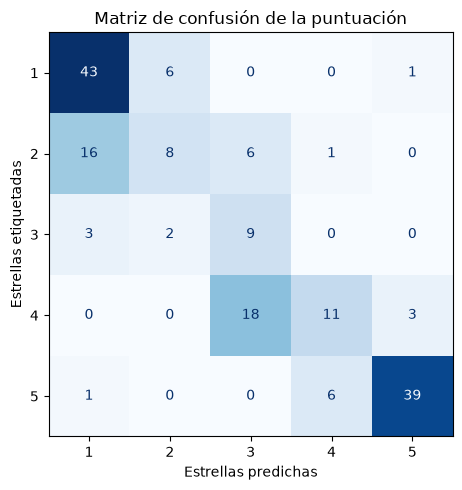

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = [1, 2, 3, 4, 5]
cm = confusion_matrix(rated["stars"], rated["pred"], labels=labels)

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_xlabel("Estrellas predichas")
ax.set_ylabel("Estrellas etiquetadas")
ax.set_title("Matriz de confusión de la puntuación")
fig.tight_layout()
fig.savefig(IMAGES / "rating_confusion_matrix.png", dpi=150)
plt.show()

### Resultados por clase

`support` es el número de reseñas etiquetadas con esa puntuación. En las clases con pocas reseñas, como 3★, las cifras son poco fiables.

In [10]:
from sklearn.metrics import classification_report

report = classification_report(rated["stars"], rated["pred"], labels=labels, output_dict=True, zero_division=0)
pd.DataFrame(report).T.loc[[str(l) for l in labels]].round(3)

,precision,recall,f1-score,support
1,0.683,0.860,0.761,50.0
2,0.500,0.258,0.340,31.0
3,0.273,0.643,0.383,14.0
4,0.611,0.344,0.440,32.0
5,0.907,0.848,0.876,46.0


### ¿Sirve la confianza?

Si `confidence` fuera fiable, las predicciones con más confianza acertarían más. Se agrupan las reseñas por tramos de confianza y se mide la accuracy en cada uno.

In [11]:
rated["tramo"] = pd.cut(rated["confidence"], bins=[0, 0.4, 0.55, 0.7, 0.85, 1.0])
by_conf = rated.groupby("tramo", observed=True).agg(
    n=("correct", "size"),
    accuracy=("correct", "mean"),
    mae=("error", lambda e: e.abs().mean()),
).round(3)
by_conf

,n,accuracy,mae
tramo,,,
"(0.0, 0.4]",9,0.444,0.889
"(0.4, 0.55]",41,0.561,0.537
"(0.55, 0.7]",53,0.547,0.472
"(0.7, 0.85]",34,0.706,0.324
"(0.85, 1.0]",36,0.833,0.194


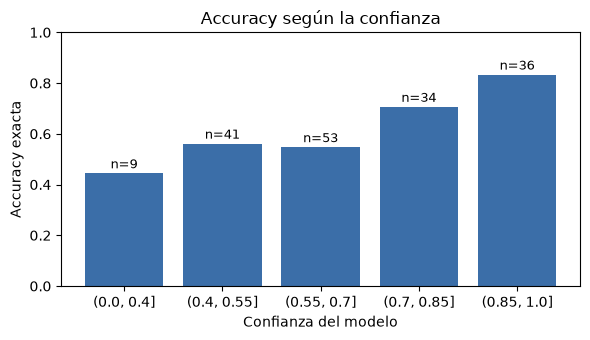

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(by_conf.index.astype(str), by_conf["accuracy"], color="#3b6ea8")
ax.set_ylim(0, 1)
ax.set_xlabel("Confianza del modelo")
ax.set_ylabel("Accuracy exacta")
ax.set_title("Accuracy según la confianza")
for i, (acc, n) in enumerate(zip(by_conf["accuracy"], by_conf["n"])):
    ax.text(i, acc + 0.02, f"n={n}", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES / "rating_confidence.png", dpi=150)
plt.show()

### Mayores errores

Las reseñas donde la predicción se aleja dos estrellas o más de la etiqueta.

In [13]:
pd.set_option("display.max_colwidth", 90)
worst = rated[rated["error"].abs() >= 2].sort_values("error", key=abs, ascending=False)
print(f"{len(worst)} reseñas con error de 2 o más estrellas")
worst[["id", "text", "stars", "pred", "confidence"]]

6 reseñas con error de 2 o más estrellas


,id,text,stars,pred,confidence
44,45,"Son todos unos ladrones hijos de perra, no vuelvo ni muerto.",1,5,0.46
159,160,Qué rico qué ricooooooooooooo sin palabras ricooooooooooooo,5,1,0.33
40,41,"El local parecía un burdel, gente desnuda y sexo explícito en el salón.",3,1,0.57
75,76,"Instalación complicada y el manual no ayuda nada, aunque una vez puesto funciona.",3,1,0.52
89,90,"La película es puro porno, escenas de sexo explícito sin ningún sentido.",3,1,0.77
188,189,Es una burla que llamen cuatro estrellas a este antro.,2,4,0.89
